In [41]:
#import warnings
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib
import matplotlib.pyplot as plt
#from itertools import product
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import seaborn as sns

In [42]:
df_2024 = pd.read_csv("../data/df_2024_final.csv").assign(season=2024)
df_2025 = pd.read_csv("../data/df_2025_final.csv").assign(season=2025)
combined = pd.concat([df_2024, df_2025], ignore_index=True)

In [43]:
#Sort chronologically by player
combined = combined.sort_values(['player_id', 'season', 'week']).reset_index(drop=True)

#Create target (Next week's fantasy score) and next week's context via shift(-1)
#FIX: group by player AND season so a season's last game doesn't take next season's week 1 as its target
g = combined.groupby(['player_id', 'season'])
combined['target_next_week_fantasy'] = g['fantasy_points'].shift(-1)
combined['next_week_opponent'] = g['opponent'].shift(-1)
combined['next_week_atVs'] = g['atVs'].shift(-1)
combined['next_week_projected'] = g['projected_points'].shift(-1)   # ESPN's projection for the game being predicted
for col in ['roof', 'surface', 'temp', 'wind', 'location']:
    combined[f'next_week_{col}'] = g[col].shift(-1)
# next_week_opp_def_rank removed: opp_def_rank is a season-end value, so it leaks future games

In [44]:
#Compute cumulative career and season-to-date stats up to current row (Week N)
stats_to_accumulate = [
    'fantasy_points', 'receptions', 'receivingTargets', 'receivingYards', 
    'receivingTouchdowns', 'rushingAttempts', 'rushingYards', 'rushingTouchdowns',
    'completions', 'passingAttempts', 'passingYards', 'passingTouchdowns', 
    'interceptions', 'fumblesLost'
]

for col in stats_to_accumulate:
    # 1. Career cumulative mean (Extract values to bypass MultiIndex mismatch)
    combined[f'{col}_cum_career_avg'] = (
        combined.groupby('player_id')[col]
        .expanding()
        .mean()
        .values
    )
    
    # 2. Season-to-date cumulative mean
    combined[f'{col}_season_avg'] = (
        combined.groupby(['player_id', 'season'])[col]
        .expanding()
        .mean()
        .values
    )

C:\Users\nisha\AppData\Local\Temp\ipykernel_3772\529716196.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  combined[f'{col}_season_avg'] = (


In [45]:
combined = combined[(combined['season'] == 2025) | (combined['season'] == 2025) & (combined['week'] < 18)]

In [46]:
categorical_cols = ['position', 'next_week_opponent', 'next_week_atVs', 'next_week_surface',
                    'next_week_roof', 'next_week_location']
for col in categorical_cols:
    if col in combined.columns:
        combined[col] = combined[col].astype('category')

In [47]:
irrelevant_columns = [
    'Unnamed: 0', 'player_id', 'player', 'team', 'opponent', 'date',
    'eventId', 'game_id', 'gameday', 'gametime', 'stadium', 'result',
    'score', 'fantasy_points', 'target_next_week_fantasy', 'espn',
    '_set', 'season',
    # FIX: leakage / wrong-game columns
    'med_proj_pts',                                   # full-season median projection (uses future weeks)
    'projected_points',                               # this week's projection; next_week_projected is used instead
    'atVs', 'roof', 'surface', 'temp', 'wind', 'location',   # current game; next_week_* versions are used
    'opp_def_rank', 'team_pass_rank', 'team_rush_rank',      # season-end ranks include future games
]

relevant_columns = [col for col in combined.columns if col not in irrelevant_columns]

In [68]:
relevant_columns

['position',
 'week',
 'receptions',
 'receivingTargets',
 'receivingYards',
 'yardsPerReception',
 'receivingTouchdowns',
 'longReception',
 'rushingAttempts',
 'rushingYards',
 'yardsPerRushAttempt',
 'longRushing',
 'rushingTouchdowns',
 'fumbles',
 'fumblesLost',
 'fumblesForced',
 'kicksBlocked',
 'completions',
 'passingAttempts',
 'passingYards',
 'completionPct',
 'yardsPerPassAttempt',
 'passingTouchdowns',
 'interceptions',
 'longPassing',
 'sacks',
 'QBRating',
 'adjQBR',
 'longFieldGoalMade',
 'fieldGoalPct',
 'fieldGoalsMadeYardsAverage',
 'totalKickingPoints',
 'totalTackles',
 'soloTackles',
 'assistTackles',
 'stuffs',
 'stuffYards',
 'fumblesRecovered',
 'interceptionYards',
 'avgInterceptionYards',
 'interceptionTouchdowns',
 'longInterception',
 'passesDefended',
 'fieldGoalsMade1_19',
 'fieldGoalAttempts1_19',
 'fieldGoalsMade20_29',
 'fieldGoalAttempts20_29',
 'fieldGoalsMade30_39',
 'fieldGoalAttempts30_39',
 'fieldGoalsMade40_49',
 'fieldGoalAttempts40_49',
 'fie

In [48]:
target = 'target_next_week_fantasy'

In [49]:
# Train: all of 2024 + 2025 weeks 1-9.  Test: 2025 week 10 onward.
train_data = combined[
    (combined['season'] == 2024) |
    ((combined['season'] == 2025) & (combined['week'] < 10))
]
test_data = combined[
    (combined['season'] == 2025) & (combined['week'] >= 10)
]
print(len(train_data), len(test_data))

3764 3808


In [50]:
X_train = train_data[relevant_columns]
y_train = train_data[target]
X_test = test_data[relevant_columns]
y_test = test_data[target]

In [51]:
train_mask = y_train.notna()
X_train, y_train = X_train[train_mask], y_train[train_mask]

test_mask = y_test.notna()
X_test, y_test = X_test[test_mask], y_test[test_mask]

In [52]:
model = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    enable_categorical=True,
    early_stopping_rounds=50      # stops when validation stops improving (old run overfit after ~50 trees)
)

In [53]:
model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50
)

[0]	validation_0-rmse:7.48790
[50]	validation_0-rmse:5.64251
[100]	validation_0-rmse:5.58213
[126]	validation_0-rmse:5.59167


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [54]:
predictions = model.predict(X_test)


--- Validation results ---
                             MAE   RMSE     R2
XGBoost                    3.980  5.572  0.462
ESPN next-week projection  3.873  5.612  0.454
Season-avg baseline        4.000  5.908  0.395


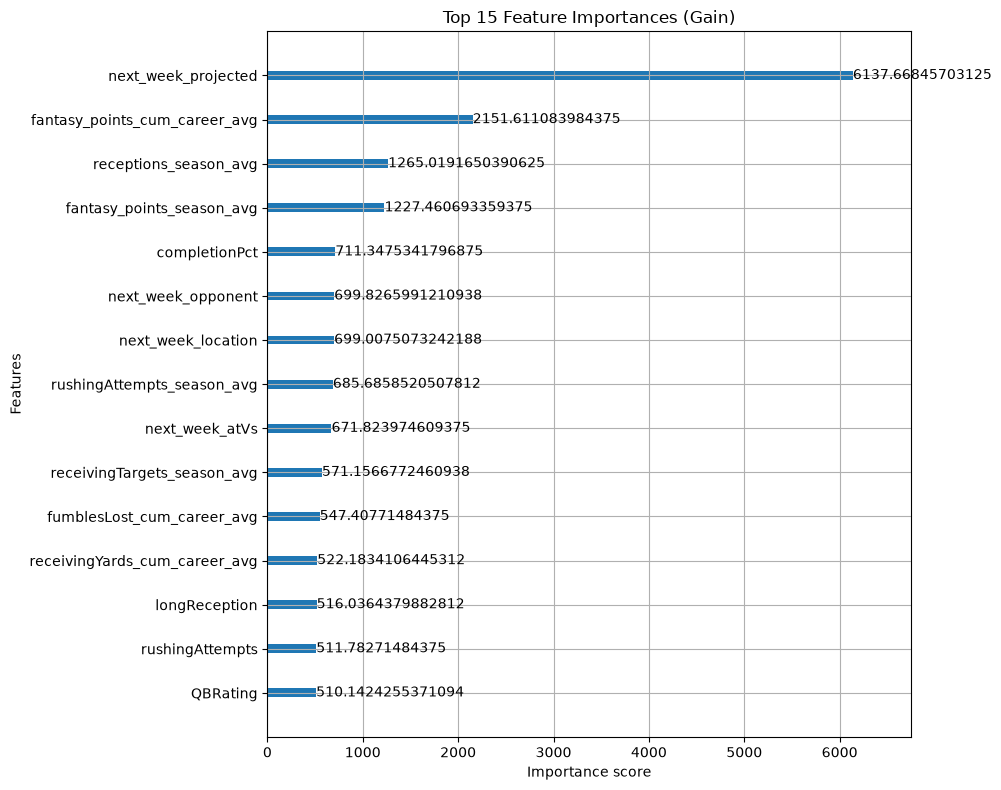

In [55]:
def metrics(y, p):
    return {"MAE": mean_absolute_error(y, p),
            "RMSE": np.sqrt(mean_squared_error(y, p)),
            "R2": r2_score(y, p)}

ok = test_data.loc[y_test.index, 'next_week_projected'].notna()
results = pd.DataFrame({
    "XGBoost": metrics(y_test, predictions),
    "ESPN next-week projection": metrics(y_test[ok], test_data.loc[y_test.index[ok], 'next_week_projected']),
    "Season-avg baseline": metrics(y_test, test_data.loc[y_test.index, 'fantasy_points_season_avg']),
}).T.round(3)
print("\n--- Validation results ---")
print(results)

# Feature Importance Plot
fig, ax = plt.subplots(figsize=(10, 8))
xgb.plot_importance(model, ax=ax, max_num_features=15, importance_type='gain')
plt.title("Top 15 Feature Importances (Gain)")
plt.tight_layout()

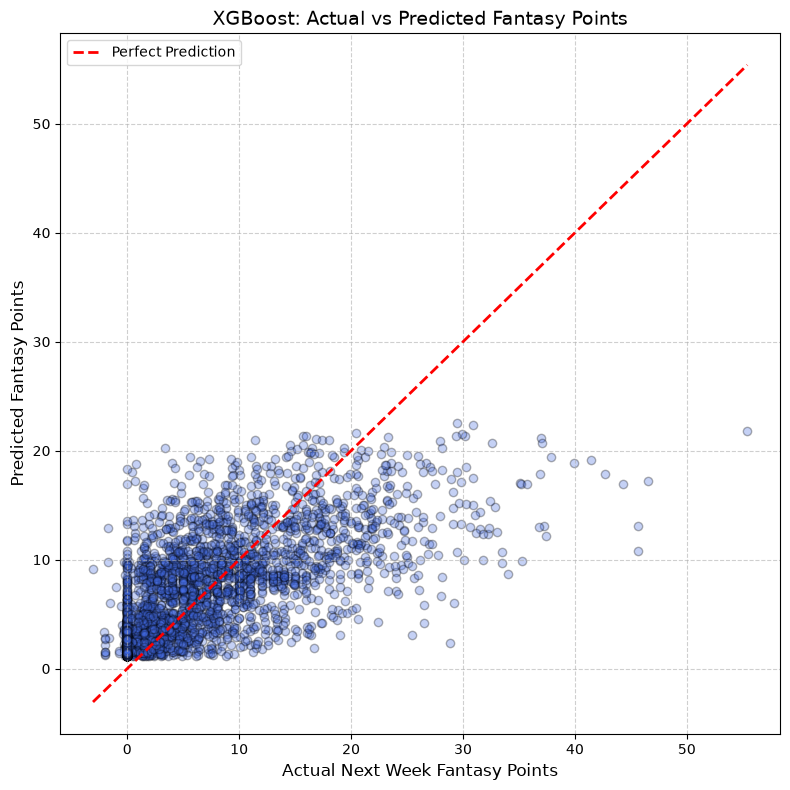

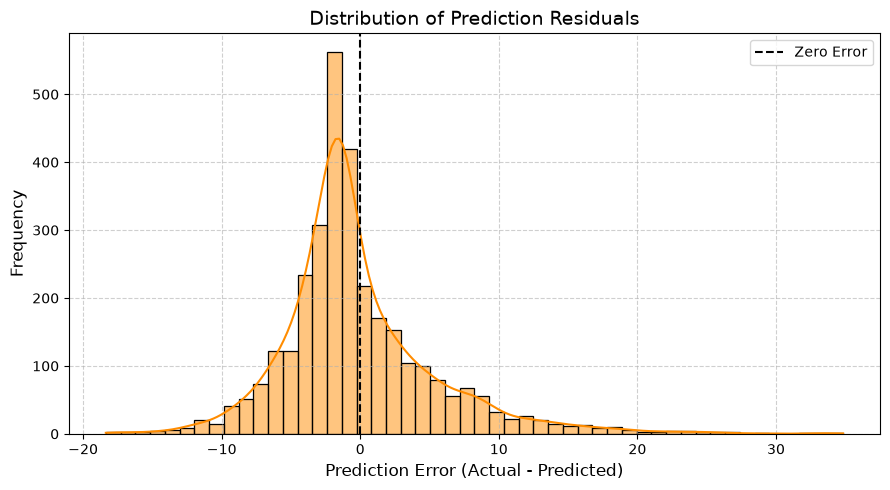

In [56]:
# 1. Actual vs Predicted Scatter Plot
plt.figure(figsize=(8, 8))
plt.scatter(y_test, predictions, alpha=0.3, color='royalblue', edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel("Actual Next Week Fantasy Points", fontsize=12)
plt.ylabel("Predicted Fantasy Points", fontsize=12)
plt.title("XGBoost: Actual vs Predicted Fantasy Points", fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()  # Displays directly in your notebook cell

# 2. Residual Distribution Plot
residuals = y_test - predictions

plt.figure(figsize=(9, 5))
sns.histplot(residuals, kde=True, color='darkorange', bins=50)
plt.axvline(0, color='black', linestyle='--', linewidth=1.5, label='Zero Error')
plt.xlabel("Prediction Error (Actual - Predicted)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.title("Distribution of Prediction Residuals", fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()  # Displays directly in your notebook cell

In [72]:
test_results = combined.loc[X_test.index].copy()
test_results['model_predicted_score'] = model.predict(X_test)
test_results['actual_score'] = test_results['fantasy_points']
test_results['actual-model_projected'] = test_results['actual_score'] - test_results['model_predicted_score']
test_results['actual-model_projected_abs'] = abs(test_results['actual-model_projected'])

# Wrap each condition in parentheses
test_results_wrong = test_results[(test_results['actual-model_projected'] > 2) | (test_results['actual-model_projected'] < -2)]
test_results_sorted = test_results_wrong.sort_values(by='actual-model_projected_abs', ascending=False)

# Make sure 'projected_points' exists, or remove it from the list if it's named differently
test_results_sorted[['season', 'week', 'player', 'position', 'team', 'actual_score', 'model_predicted_score', 'projected_points', 'actual-model_projected', 'actual-model_projected_abs']].head(10)

,season,week,player,position,team,actual_score,model_predicted_score,projected_points,actual-model_projected,actual-model_projected_abs
11642,2025,12,Jahmyr Gibbs,RB,DET,55.40,18.363478,21.023432,37.036522,37.036522
7938,2025,15,Kyle Pitts Sr.,TE,ATL,45.60,10.812549,11.904759,34.787451,34.787451
6808,2025,10,Jonathan Taylor,RB,IND,49.60,15.384855,21.248837,34.215145,34.215145
8005,2025,15,Trevor Lawrence,QB,JAX,44.30,12.451208,17.288336,31.848792,31.848792
1724,2025,17,Derrick Henry,RB,BAL,45.60,14.207203,13.268134,31.392797,31.392797
1169,2025,12,Jameis Winston,QB,NYG,32.24,3.326681,13.909762,28.913319,28.913319
4317,2025,11,Josh Allen,QB,BUF,42.68,14.565315,20.697483,28.114685,28.114685
8213,2025,14,Michael Wilson,WR,ARI,37.20,11.027589,14.941974,26.172411,26.172411
10637,2025,16,Puka Nacua,WR,LAR,46.50,20.499992,19.844443,26.000008,26.000008
8471,2025,15,Trey McBride,TE,ARI,37.40,13.657241,14.043909,23.742759,23.742759


In [62]:
print(combined.columns.tolist())

['Unnamed: 0', 'player_id', 'player', 'position', 'team', 'season', 'week', 'eventId', 'date', 'opponent', 'atVs', 'result', 'score', 'receptions', 'receivingTargets', 'receivingYards', 'yardsPerReception', 'receivingTouchdowns', 'longReception', 'rushingAttempts', 'rushingYards', 'yardsPerRushAttempt', 'longRushing', 'rushingTouchdowns', 'fumbles', 'fumblesLost', 'fumblesForced', 'kicksBlocked', 'completions', 'passingAttempts', 'passingYards', 'completionPct', 'yardsPerPassAttempt', 'passingTouchdowns', 'interceptions', 'longPassing', 'sacks', 'QBRating', 'adjQBR', 'longFieldGoalMade', 'fieldGoalPct', 'fieldGoalsMadeYardsAverage', 'totalKickingPoints', 'totalTackles', 'soloTackles', 'assistTackles', 'stuffs', 'stuffYards', 'fumblesRecovered', 'interceptionYards', 'avgInterceptionYards', 'interceptionTouchdowns', 'longInterception', 'passesDefended', 'fieldGoalsMade1_19', 'fieldGoalAttempts1_19', 'fieldGoalsMade20_29', 'fieldGoalAttempts20_29', 'fieldGoalsMade30_39', 'fieldGoalAttempt